# ECG Heartbeat Arrhythmia Classification Using Deep ANN

## CSE 532 - Machine Learning

### Project Objective

The objective of this project is to develop a Deep Artificial Neural
Network for classifying ECG heartbeat signals into five categories
using the MIT-BIH Arrhythmia dataset.

The project investigates data preprocessing, class imbalance,
neural network architectures, optimization techniques,
and multiclass classification performance.

**Methodology note:** Model selection uses the validation split and Macro F1. The official test split is used only for final evaluation. This dataset is pre-segmented, and the split may not be patient-independent.

In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn tensorflow imbalanced-learn joblib flask

Note: you may need to restart the kernel to use updated packages.


## 1. Import libraries

In [2]:
# Import core Python and machine learning libraries.\nimport os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from tensorflow.keras.optimizers import Adam

print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

All libraries imported successfully!
TensorFlow Version: 2.22.0-rc1


## 2. Reproducibility

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed fixed:", SEED)

Random seed fixed: 42


## 3. Load the dataset

In [4]:
from pathlib import Path
import pandas as pd

# Resolve the project root whether the notebook is opened from root or notebooks/.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATASET_DIR = PROJECT_ROOT / "dataset"
MODEL_DIR = PROJECT_ROOT / "models"
PLOT_DIR = PROJECT_ROOT / "results" / "plots"
REPORT_DIR = PROJECT_ROOT / "results" / "reports"

# Create output directories before saving plots, reports, or model files.
for folder in (MODEL_DIR, PLOT_DIR, REPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

train_path = DATASET_DIR / "mitbih_train.csv"
test_path = DATASET_DIR / "mitbih_test.csv"

train_df = pd.read_csv(train_path, header=None)
test_df = pd.read_csv(test_path, header=None)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)
print("Project Root:", PROJECT_ROOT)

Training Dataset Shape: (87554, 188)
Testing Dataset Shape: (21892, 188)
Project Root: C:\Users\waqas\Desktop\ECG_Heartbeat_Classification


10. Explore the dataset

In [5]:
train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Data types

In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87554 entries, 0 to 87553
Columns: 188 entries, 0 to 187
dtypes: float64(188)
memory usage: 125.6 MB


### Descriptive statistics

In [7]:
train_df.describe()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
count,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,...,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000,87554.000000
mean,0.890360,0.758160,0.423972,0.219104,0.201127,0.210399,0.205808,0.201773,0.198691,0.196757,...,0.005025,0.004628,0.004291,0.003945,0.003681,0.003471,0.003221,0.002945,0.002807,0.473376
std,0.240909,0.221813,0.227305,0.206878,0.177058,0.171909,0.178481,0.177240,0.171778,0.168357,...,0.044154,0.042089,0.040525,0.038651,0.037193,0.036255,0.034789,0.032865,0.031924,1.143184
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.921922,0.682486,0.250969,0.048458,0.082329,0.088416,0.073333,0.066116,0.065000,0.068639,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.991342,0.826013,0.429472,0.166000,0.147878,0.158798,0.145324,0.144424,0.150000,0.148734,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.910506,0.578767,0.341727,0.258993,0.287628,0.298237,0.295391,0.290832,0.283636,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000


### Missing values

In [8]:
print("Training Missing Values:", train_df.isnull().sum().sum())
print("Testing Missing Values:", test_df.isnull().sum().sum())

Training Missing Values: 0
Testing Missing Values: 0


### Duplicate records

In [9]:
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


## 4. Exploratory Data Analysis (EDA)

### Class distribution

In [10]:
class_names = {
    0: "Normal (N)",
    1: "Supraventricular (S)",
    2: "Ventricular (V)",
    3: "Fusion (F)",
    4: "Unknown (Q)"
}

class_counts = train_df.iloc[:, -1].value_counts().sort_index()

print(class_counts)

187
0.0    72471
1.0     2223
2.0     5788
3.0      641
4.0     6431
Name: count, dtype: int64


### Class distribution plot

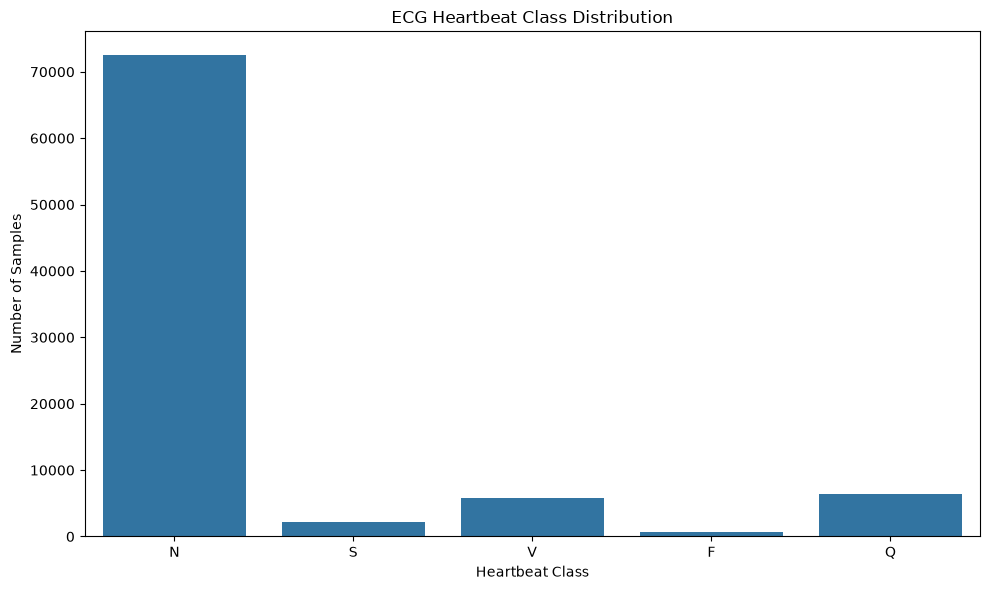

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("ECG Heartbeat Class Distribution")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Samples")

plt.xticks(
    ticks=[0, 1, 2, 3, 4],
    labels=["N", "S", "V", "F", "Q"]
)

plt.tight_layout()
plt.show()

### ECG waveform visualization

### Single ECG waveform

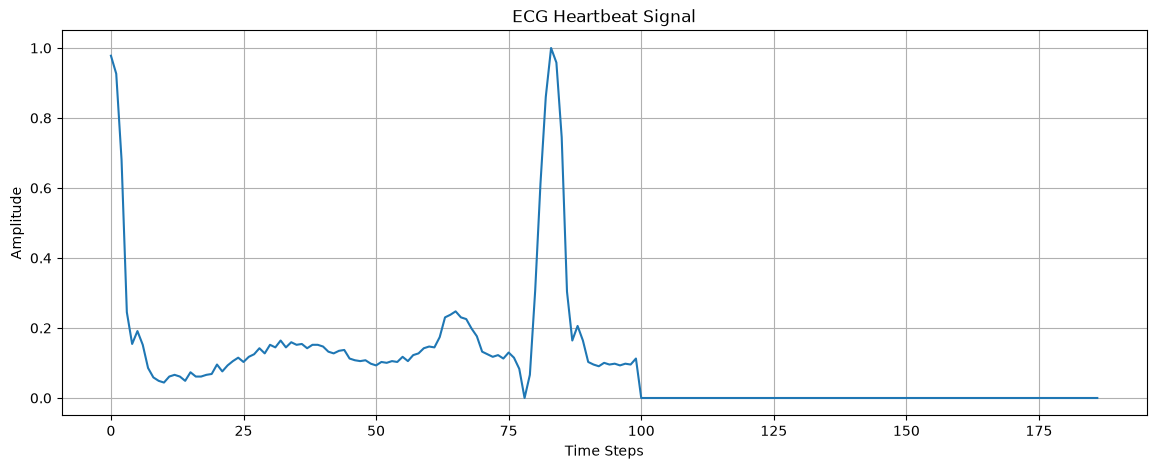

In [12]:
sample = train_df.iloc[0, :187].values

plt.figure(figsize=(14, 5))

plt.plot(sample)

plt.title("ECG Heartbeat Signal")
plt.xlabel("Time Steps")
plt.ylabel("Amplitude")

plt.grid(True)
plt.show()

### Waveforms by class

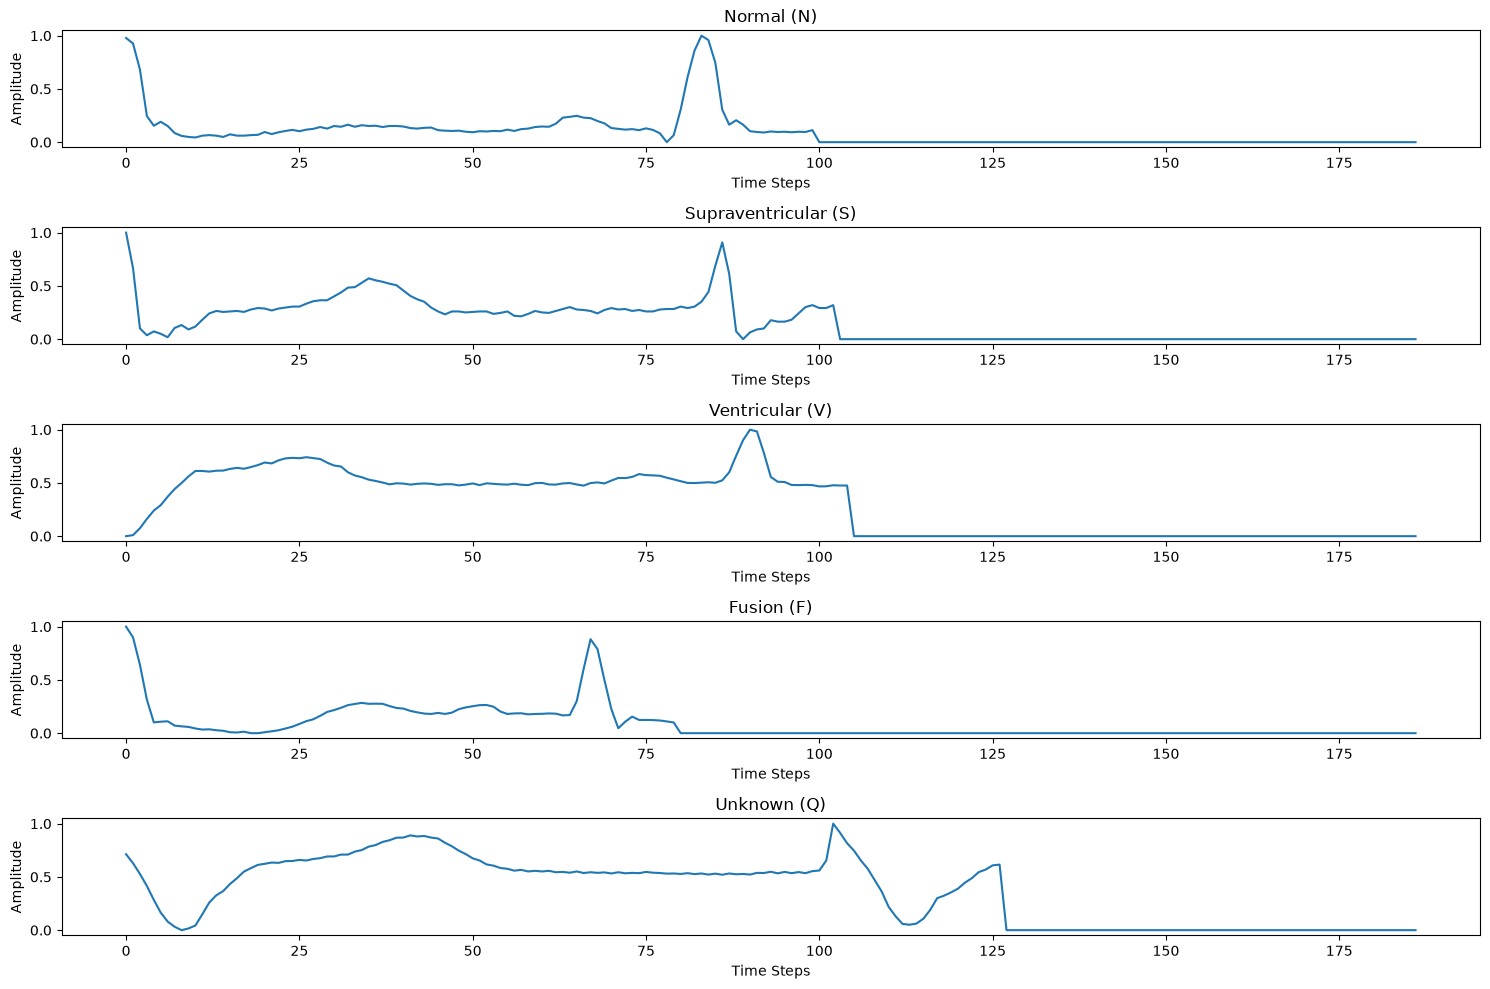

In [13]:
plt.figure(figsize=(15, 10))

for class_id in range(5):

    sample_index = train_df[
        train_df.iloc[:, -1] == class_id
    ].index[0]

    signal = train_df.iloc[sample_index, :187].values

    plt.subplot(5, 1, class_id + 1)

    plt.plot(signal)

    plt.title(class_names[class_id])

    plt.xlabel("Time Steps")
    plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

## 5. Data preprocessing

In [14]:
X_train_full = train_df.iloc[:, :-1].values
y_train_full = train_df.iloc[:, -1].values.astype(int)

X_test = test_df.iloc[:, :-1].values
y_test = test_df.iloc[:, -1].values.astype(int)

print("X Training:", X_train_full.shape)
print("y Training:", y_train_full.shape)

print("X Testing:", X_test.shape)
print("y Testing:", y_test.shape)

X Training: (87554, 187)
y Training: (87554,)
X Testing: (21892, 187)
y Testing: (21892,)


### Train-validation split

In [15]:
# Split the original training set; the official test set remains untouched.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Final Testing:", X_test.shape)

Training: (70043, 187)
Validation: (17511, 187)
Final Testing: (21892, 187)


### Feature scaling

In [16]:
# Fit on training data only and apply the same transformation to validation/test.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")

print("Train mean:", np.mean(X_train_scaled))
print("Train standard deviation:", np.std(X_train_scaled))

Scaling completed!
Train mean: -1.006843174159209e-17
Train standard deviation: 1.0000000000000013


## 6. Class imbalance handling

In [17]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(0.2416234023837039), np.int64(1): np.float64(7.878852643419573), np.int64(2): np.float64(3.0256155507559397), np.int64(3): np.float64(27.307212475633527), np.int64(4): np.float64(2.722759961127308)}


## 7. Feedforward ANN experiments

### ANN architecture

### Baseline ANN

In [18]:
baseline_model = Sequential([
    Dense(64, activation="relu", input_shape=(187,)),
    Dense(5, activation="softmax")
])

baseline_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

C:\Users\waqas\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │          12,032 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,357 (48.27 KB)

 Trainable params: 12,357 (48.27 KB)

 Non-trainable params: 0 (0.00 B)

### Baseline training

In [19]:
baseline_history = baseline_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=20,
    batch_size=128,
    verbose=1
)

Epoch 1/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9219 - loss: 0.2883 - val_accuracy: 0.9537 - val_loss: 0.1848
Epoch 2/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9564 - loss: 0.1666 - val_accuracy: 0.9613 - val_loss: 0.1524
Epoch 3/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9619 - loss: 0.1415 - val_accuracy: 0.9649 - val_loss: 0.1356
Epoch 4/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9653 - loss: 0.1271 - val_accuracy: 0.9667 - val_loss: 0.1268
Epoch 5/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9680 - loss: 0.1166 - val_accuracy: 0.9685 - val_loss: 0.1196
Epoch 6/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9701 - loss: 0.1092 - val_accuracy: 0.9697 - val_loss: 0.1147
Epoch 7/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9716 - loss: 0.1034 - val_accuracy: 0.9698 - val_loss: 0.1117
Epoch 8/20
548/548 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9727 - loss: 0.0989 - val_accuracy: 0.

### Baseline accuracy curve

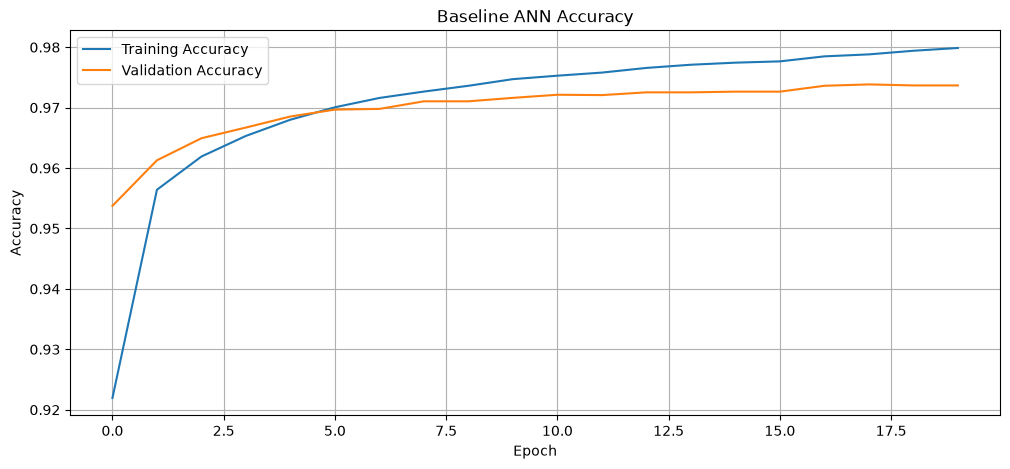

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    baseline_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    baseline_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

### Baseline loss curve

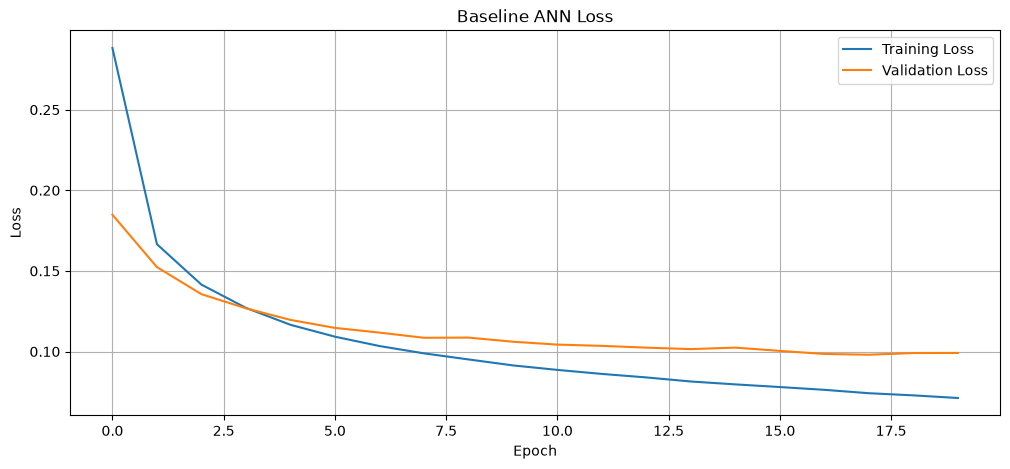

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(
    baseline_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    baseline_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

### Dropout regularization
Dropout randomly disables a fraction of neurons during training to help reduce overfitting.

### Build the deep ANN

In [22]:
deep_model = Sequential([

    Dense(256, activation="relu", input_shape=(187,)),
    BatchNormalization(),
    Dropout(0.30),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.30),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(32, activation="relu"),

    Dense(5, activation="softmax")
])

deep_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

deep_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 256)                 │          48,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,317 (364.52 KB)

 Trainable params: 92,421 (361.02 KB)

 Non-trainable params: 896 (3.50 KB)

### Training callbacks

In [23]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

checkpoint = ModelCheckpoint(
    MODEL_DIR / "best_deep_ann.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

### Deep ANN training

In [24]:
# Add batch normalization and dropout to improve generalization.
deep_history = deep_model.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=50,
    batch_size=128,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5170 - loss: 0.7806
Epoch 1: val_loss improved from None to 0.69729, saving model to C:\Users\waqas\Desktop\ECG_Heartbeat_Classification\models\best_deep_ann.keras

Epoch 1: finished saving model to C:\Users\waqas\Desktop\ECG_Heartbeat_Classification\models\best_deep_ann.keras
548/548 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.5170 - loss: 0.7806 - val_accuracy: 0.7424 - val_loss: 0.6973 - learning_rate: 0.0010
Epoch 2/50
547/548 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6972 - loss: 0.5532
Epoch 2: val_loss improved from 0.69729 to 0.54766, saving model to C:\Users\waqas\Desktop\ECG_Heartbeat_Classification\models\best_deep_ann.keras

Epoch 2: finished saving model to C:\Users\waqas\Desktop\ECG_Heartbeat_Classification\models\best_deep_ann.keras
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.6972 - loss: 0.5532 - val_accuracy: 0.8039 - val_loss: 0.5477 - learning_rate: 0.0010
Epoch 3/50
545/548 ━━

### Deep ANN learning curves

### Deep ANN accuracy

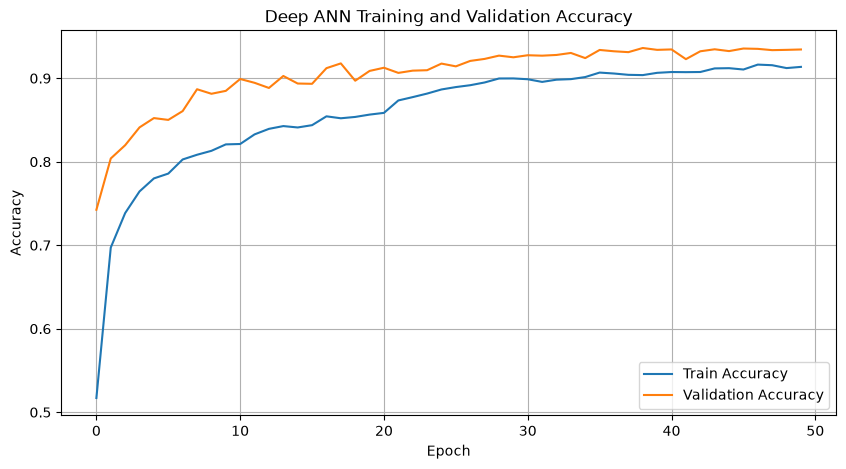

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    deep_history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    deep_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Deep ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(PLOT_DIR / "deep_ann_accuracy.png", dpi=300)

plt.show()

### Deep ANN loss

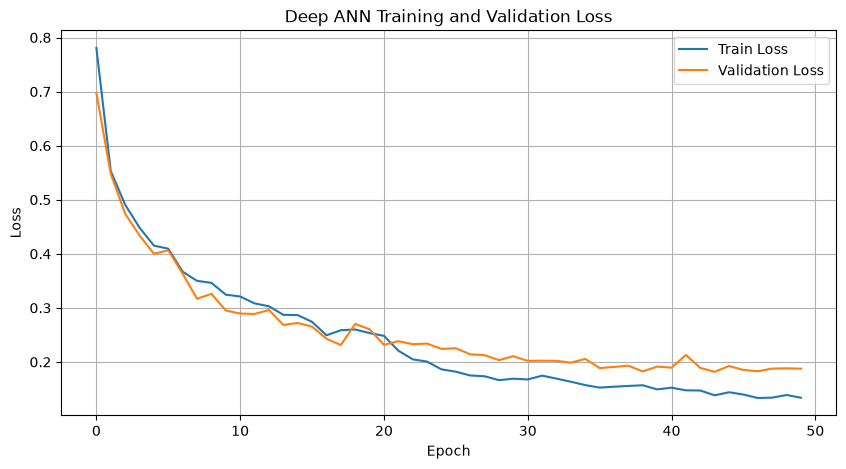

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    deep_history.history["loss"],
    label="Train Loss"
)

plt.plot(
    deep_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Deep ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.savefig(PLOT_DIR / "deep_ann_loss.png", dpi=300)

plt.show()

### Optimized ANN (Swish)

### Swish activation
The optimized model uses the Swish activation function instead of ReLU to compare activation choices.

In [27]:
optimized_model = Sequential([

    Dense(256, activation="swish", input_shape=(187,)),
    BatchNormalization(),
    Dropout(0.30),

    Dense(128, activation="swish"),
    BatchNormalization(),
    Dropout(0.30),

    Dense(64, activation="swish"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(32, activation="swish"),

    Dense(5, activation="softmax")
])

optimized_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

optimized_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 256)                 │          48,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,317 (364.52 KB)

 Trainable params: 92,421 (361.02 KB)

 Non-trainable params: 896 (3.50 KB)

### Optimized ANN Training

In [28]:
optimized_history = optimized_model.fit(
    X_train_scaled,
    y_train,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=50,
    batch_size=128,

    class_weight=class_weights,

    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=0.00001,
            verbose=1
        )
    ],

    verbose=1
)

Epoch 1/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.5994 - loss: 0.7537 - val_accuracy: 0.7760 - val_loss: 0.6625 - learning_rate: 0.0010
Epoch 2/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.7228 - loss: 0.5342 - val_accuracy: 0.8152 - val_loss: 0.5395 - learning_rate: 0.0010
Epoch 3/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.7555 - loss: 0.4800 - val_accuracy: 0.8387 - val_loss: 0.4666 - learning_rate: 0.0010
Epoch 4/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.7812 - loss: 0.4320 - val_accuracy: 0.8517 - val_loss: 0.4186 - learning_rate: 0.0010
Epoch 5/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.7891 - loss: 0.4031 - val_accuracy: 0.8531 - val_loss: 0.3833 - learning_rate: 0.0010
Epoch 6/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.8015 - loss: 0.3821 - val_accuracy: 0.8725 - val_loss: 0.3720 - learning_rate: 0.0010
Epoch 7/50
548/548 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.8086 - l

## 9. SMOTE experiment

### Resample training data

In [29]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    sampling_strategy="not majority"
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:", X_train_scaled.shape)
print("After SMOTE:", X_train_smote.shape)

print("\nOriginal class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nSMOTE class distribution:")
print(pd.Series(y_train_smote).value_counts().sort_index())

Before SMOTE: (70043, 187)
After SMOTE: (289885, 187)

Original class distribution:
0    57977
1     1778
2     4630
3      513
4     5145
Name: count, dtype: int64

SMOTE class distribution:
0    57977
1    57977
2    57977
3    57977
4    57977
Name: count, dtype: int64


### Train SMOTE ANN

In [30]:
smote_model = Sequential([

    Dense(256, activation="relu", input_shape=(187,)),
    BatchNormalization(),
    Dropout(0.30),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.30),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(32, activation="relu"),

    Dense(5, activation="softmax")
])

smote_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

C:\Users\waqas\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
smote_history = smote_model.fit(
    X_train_smote,
    y_train_smote,

    validation_data=(
        X_val_scaled,
        y_val
    ),

    epochs=50,
    batch_size=128,

    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=7,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3
        )
    ],

    verbose=1
)

Epoch 1/50
2265/2265 ━━━━━━━━━━━━━━━━━━━━ 34s 12ms/step - accuracy: 0.8809 - loss: 0.3242 - val_accuracy: 0.8900 - val_loss: 0.2935 - learning_rate: 0.0010
Epoch 2/50
2265/2265 ━━━━━━━━━━━━━━━━━━━━ 32s 11ms/step - accuracy: 0.9379 - loss: 0.1737 - val_accuracy: 0.9296 - val_loss: 0.2027 - learning_rate: 0.0010
Epoch 3/50
2265/2265 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.9514 - loss: 0.1392 - val_accuracy: 0.9328 - val_loss: 0.1962 - learning_rate: 0.0010
Epoch 4/50
2265/2265 ━━━━━━━━━━━━━━━━━━━━ 40s 11ms/step - accuracy: 0.9588 - loss: 0.1189 - val_accuracy: 0.9403 - val_loss: 0.1763 - learning_rate: 0.0010
Epoch 5/50
2265/2265 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.9630 - loss: 0.1066 - val_accuracy: 0.9439 - val_loss: 0.1641 - learning_rate: 0.0010
Epoch 6/50
2265/2265 ━━━━━━━━━━━━━━━━━━━━ 42s 11ms/step - accuracy: 0.9666 - loss: 0.0975 - val_accuracy: 0.9539 - val_loss: 0.1406 - learning_rate: 0.0010
Epoch 7/50
2265/2265 ━━━━━━━━━━━━━━━━━━━━ 40s 11ms/step - accura

## 10. Model comparison

### Validation comparison table

In [32]:
# Compare models on validation data only; reserve the test set for final evaluation.
models = {
    "Baseline ANN": baseline_model,
    "Deep ANN": deep_model,
    "Optimized ANN": optimized_model,
    "SMOTE ANN": smote_model
}

validation_results = []

for name, model in models.items():
    val_predictions = np.argmax(model.predict(X_val_scaled, verbose=0), axis=1)
    validation_results.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_val, val_predictions),
        "Validation Macro Precision": precision_score(y_val, val_predictions, average="macro", zero_division=0),
        "Validation Macro Recall": recall_score(y_val, val_predictions, average="macro", zero_division=0),
        "Validation Macro F1": f1_score(y_val, val_predictions, average="macro", zero_division=0),
        "Validation Weighted F1": f1_score(y_val, val_predictions, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(validation_results).sort_values("Validation Macro F1", ascending=False)
display(results_df)

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
print("Selected model based on validation Macro F1:", best_model_name)

,Model,Validation Accuracy,Validation Macro Precision,Validation Macro Recall,Validation Macro F1,Validation Weighted F1
3,SMOTE ANN,0.975672,0.852007,0.916660,0.880759,0.976370
0,Baseline ANN,0.973674,0.925339,0.827880,0.868703,0.972517
1,Deep ANN,0.934670,0.702753,0.924050,0.770980,0.943737
2,Optimized ANN,0.929016,0.692359,0.923908,0.757941,0.940082


Selected model based on validation Macro F1: SMOTE ANN


### Comparison plot

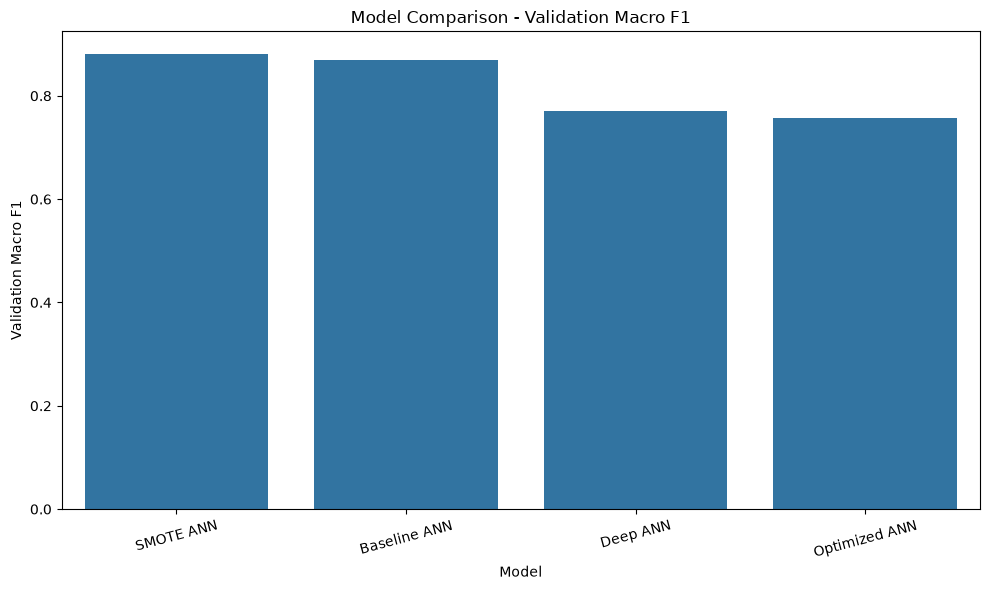

In [33]:
# Visualize validation Macro F1 scores for model selection.
plt.figure(figsize=(10, 6))
sns.barplot(data=results_df, x="Model", y="Validation Macro F1")
plt.title("Model Comparison - Validation Macro F1")
plt.xlabel("Model")
plt.ylabel("Validation Macro F1")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(PLOT_DIR / "model_comparison.png", dpi=300)
plt.show()

## 11. Final evaluation on the held-out test set

### Final test evaluation

In [34]:
test_loss, test_accuracy = best_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1
)

print("Final Test Loss:", test_loss)
print("Final Test Accuracy:", test_accuracy)

685/685 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9750 - loss: 0.1090
Final Test Loss: 0.10899049788713455
Final Test Accuracy: 0.9749680161476135


### Generate test predictions

In [35]:
y_prob = best_model.predict(
    X_test_scaled,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

print("Predictions generated!")
print("Prediction shape:", y_pred.shape)

685/685 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predictions generated!
Prediction shape: (21892,)


### Classification metrics

In [36]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=["N", "S", "V", "F", "Q"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           N     0.9908    0.9827    0.9867     18118
           S     0.6836    0.8004    0.7374       556
           V     0.9333    0.9468    0.9400      1448
           F     0.7196    0.8395    0.7749       162
           Q     0.9845    0.9876    0.9860      1608

    accuracy                         0.9750     21892
   macro avg     0.8623    0.9114    0.8850     21892
weighted avg     0.9767    0.9750    0.9757     21892



### Confusion matrix

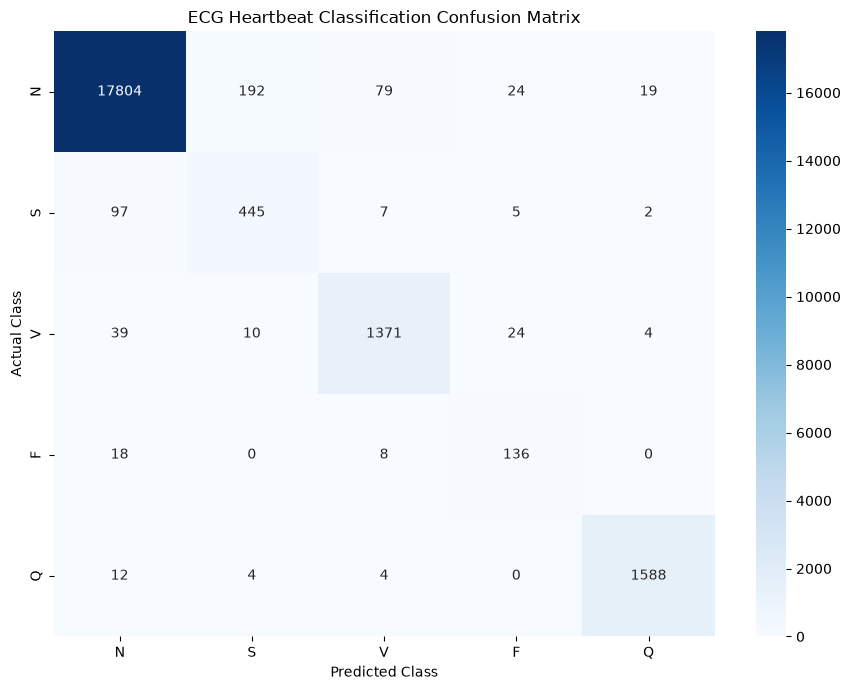

In [37]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["N", "S", "V", "F", "Q"],
    yticklabels=["N", "S", "V", "F", "Q"]
)

plt.title("ECG Heartbeat Classification Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()

## 12. Model interpretation

In [38]:
def calculate_permutation_importance(
    model,
    X,
    y,
    n_repeats=3
):

    baseline_predictions = np.argmax(
        model.predict(X, verbose=0),
        axis=1
    )

    baseline_score = f1_score(
        y,
        baseline_predictions,
        average="macro"
    )

    feature_importances = []

    rng = np.random.default_rng(42)

    for feature in range(X.shape[1]):

        scores = []

        for repeat in range(n_repeats):

            X_permuted = X.copy()

            shuffled_values = X_permuted[:, feature].copy()

            rng.shuffle(shuffled_values)

            X_permuted[:, feature] = shuffled_values

            predictions = np.argmax(
                model.predict(
                    X_permuted,
                    verbose=0
                ),
                axis=1
            )

            score = f1_score(
                y,
                predictions,
                average="macro"
            )

            scores.append(score)

        importance = baseline_score - np.mean(scores)

        feature_importances.append(importance)

    return np.array(feature_importances)

### Permutation importance

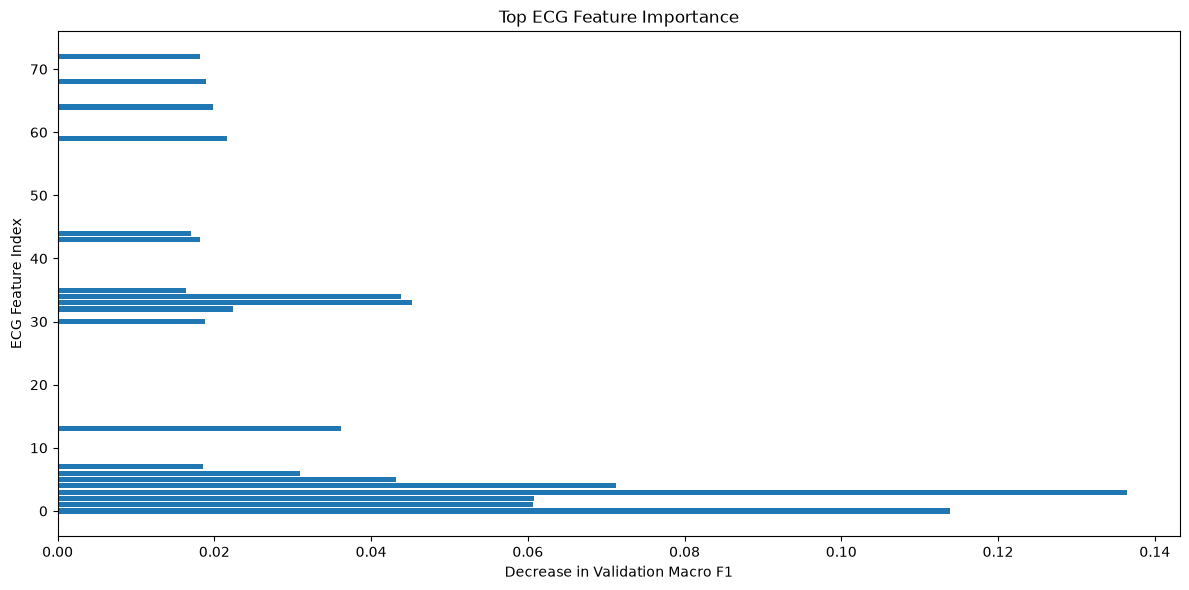

In [39]:
# Estimate feature importance using validation samples, not the final test set.
importance = calculate_permutation_importance(
    best_model,
    X_val_scaled[:3000],
    y_val[:3000],
    n_repeats=2
)

top_indices = np.argsort(importance)[-20:]

plt.figure(figsize=(12, 6))
plt.barh(top_indices, importance[top_indices])
plt.title("Top ECG Feature Importance")
plt.xlabel("Decrease in Validation Macro F1")
plt.ylabel("ECG Feature Index")
plt.tight_layout()
plt.savefig(PLOT_DIR / "feature_importance.png", dpi=300)
plt.show()

## 13. Save model and artifacts

### Save the model

In [40]:
# Ensure output directories exist before saving files.
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

In [41]:
# Save the selected neural network.
best_model.save(MODEL_DIR / "ecg_best_ann.keras")

In [43]:
import joblib
# Save the fitted preprocessing scaler used during model training.
joblib.dump(scaler, MODEL_DIR / "ecg_scaler.pkl")
print("Model and scaler saved successfully!")

Model and scaler saved successfully!


## 14. Flask web application

### Run and test the Flask app

The Flask code is in `app/app.py`, and the HTML interface is in `app/templates/index.html`. Do not paste Flask or HTML code into notebook cells.

After the notebook has saved `models/ecg_best_ann.keras` and `models/ecg_scaler.pkl`:

1. Open a terminal in the project root.
2. Install dependencies with `pip install -r requirements.txt`.
3. Run `python app/app.py`.
4. Open `http://127.0.0.1:5000` in your browser.
5. Upload `results/reports/sample_ecg.csv` (created by the notebook).

The CSV must contain 187 numeric columns per row and no target-label column.

### Export a sample input file

In [44]:
# Export five test examples without class labels for testing the web application.
sample_ecg_df = pd.DataFrame(X_test[:5])
sample_ecg_df.to_csv(REPORT_DIR / "sample_ecg.csv", index=False, header=False)
print("Sample ECG CSV saved:", REPORT_DIR / "sample_ecg.csv")

Sample ECG CSV saved: C:\Users\waqas\Desktop\ECG_Heartbeat_Classification\results\reports\sample_ecg.csv


## 15. Export research results

### Export comparison results

In [45]:
# Export the validation-based model comparison.
results_df.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
print("Validation comparison saved.")

Validation comparison saved.


### Save classification report

In [46]:
# Save the final test classification report.
final_report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["N", "S", "V", "F", "Q"],
    digits=4,
    zero_division=0
)

(REPORT_DIR / "final_classification_report.txt").write_text(final_report, encoding="utf-8")
print(final_report)

              precision    recall  f1-score   support

           N     0.9908    0.9827    0.9867     18118
           S     0.6836    0.8004    0.7374       556
           V     0.9333    0.9468    0.9400      1448
           F     0.7196    0.8395    0.7749       162
           Q     0.9845    0.9876    0.9860      1608

    accuracy                         0.9750     21892
   macro avg     0.8623    0.9114    0.8850     21892
weighted avg     0.9767    0.9750    0.9757     21892



### Final model summary

In [47]:
# Save a compact summary of the final test metrics.
final_results = {
    "Selected Model": best_model_name,
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Test Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Test Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0)
}

final_results_df = pd.DataFrame([final_results])
final_results_df.to_csv(REPORT_DIR / "final_model_summary.csv", index=False)
final_results_df

,Selected Model,Test Accuracy,Test Macro F1,Test Weighted F1
0,SMOTE ANN,0.974968,0.885006,0.975662


## 16. Additional analysis

### Per-class recall

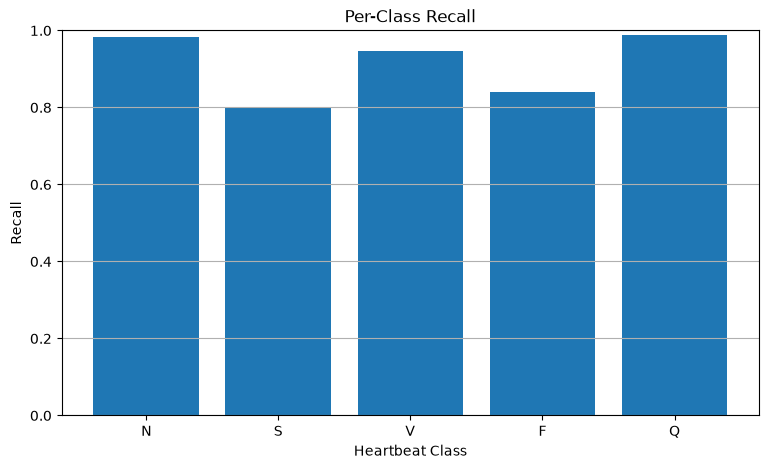

In [48]:
report_dict = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["N", "S", "V", "F", "Q"],
    output_dict=True,
    zero_division=0
)

recall_values = [
    report_dict[name]["recall"]
    for name in ["N", "S", "V", "F", "Q"]
]

plt.figure(figsize=(9, 5))

plt.bar(
    ["N", "S", "V", "F", "Q"],
    recall_values
)

plt.title("Per-Class Recall")
plt.xlabel("Heartbeat Class")
plt.ylabel("Recall")

plt.ylim(0, 1)

plt.grid(axis="y")
plt.show()

### Prediction confidence

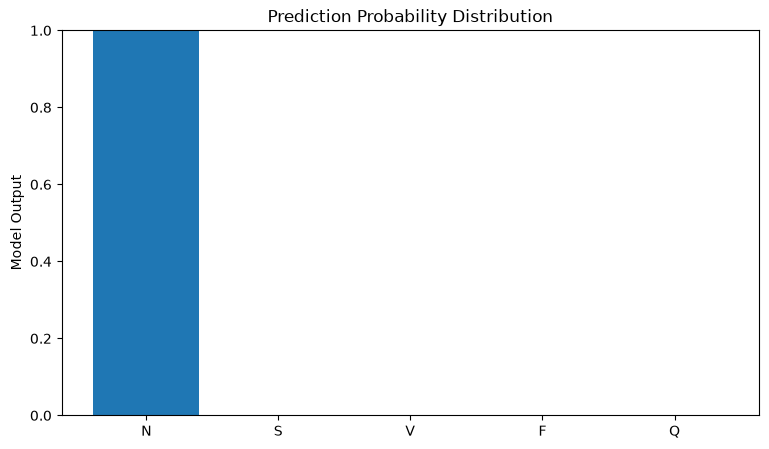

In [49]:
sample_index = 0

probabilities = best_model.predict(
    X_test_scaled[sample_index:sample_index+1],
    verbose=0
)[0]

plt.figure(figsize=(9, 5))

plt.bar(
    ["N", "S", "V", "F", "Q"],
    probabilities
)

plt.title("Prediction Probability Distribution")
plt.ylabel("Model Output")

plt.ylim(0, 1)
plt.show()

### Validation-only feature importance

In [50]:
importance = calculate_permutation_importance(
    best_model,
    X_val_scaled[:3000],
    y_val[:3000],
    n_repeats=2
)